# 🚀 Модуль 4. Урок 3. Поиск аномалий и выбросов: одномерные и многомерные методы (Isolation Forest)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_04_data_cleaning/lesson_03_outliers_anomaly_detection.ipynb)

## 📌 Бизнес-контекст и методология
Выброс по одной переменной заметить легко (заказ на $1,000,000). 
Но в реальной жизни самые опасные аномалии — **многомерные**. 
Например: заказ на $50 — норма. Заказ 100 товаров — тоже норма (опт). Но заказ на $50, состоящий из 100 товаров — это очевидный баг ценообразования или уязвимость промокода.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

orders_csv = ensure_dataset("orders.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Смоделируем многомерные данные заказов: сумма заказа (`amount`) и количество позиций (`items_count`), содержащие скрытые аномалии.

In [2]:
from sklearn.ensemble import IsolationForest
import numpy as np
import pandas as pd

np.random.seed(42)
# Обычные заказы: положительная корреляция между суммой и количеством товаров
n_normal = 400
normal_items = np.random.randint(1, 8, n_normal)
normal_amount = normal_items * 25 + np.random.normal(10, 8, n_normal)

# Аномалии (скрытый фрод / баги промокодов)
# 1) Огромная сумма при 1 товаре (ошибка ввода)
# 2) 50 товаров при чеке $10 (баг скидки 99%)
anom_items = np.array([1, 1, 45, 60, 2])
anom_amount = np.array([850, 920, 15, 25, 780])

all_items = np.concatenate([normal_items, anom_items])
all_amounts = np.concatenate([normal_amount, anom_amount])
df_orders = pd.DataFrame({'items_count': all_items, 'amount': all_amounts})

# Обучаем Isolation Forest
iso = IsolationForest(contamination=0.015, random_state=42)
df_orders['is_anomaly'] = iso.fit_predict(df_orders[['items_count', 'amount']])

anom_count = (df_orders['is_anomaly'] == -1).sum()
print(f"Обнаружено аномальных заказов через Isolation Forest: {anom_count}")

Обнаружено аномальных заказов через Isolation Forest: 7


### 📊 Визуализация: Контуры решений Isolation Forest
На графике ниже синие точки — легитимные заказы бизнеса, а красные — аномалии, изолированные алгоритмом в многомерном пространстве.

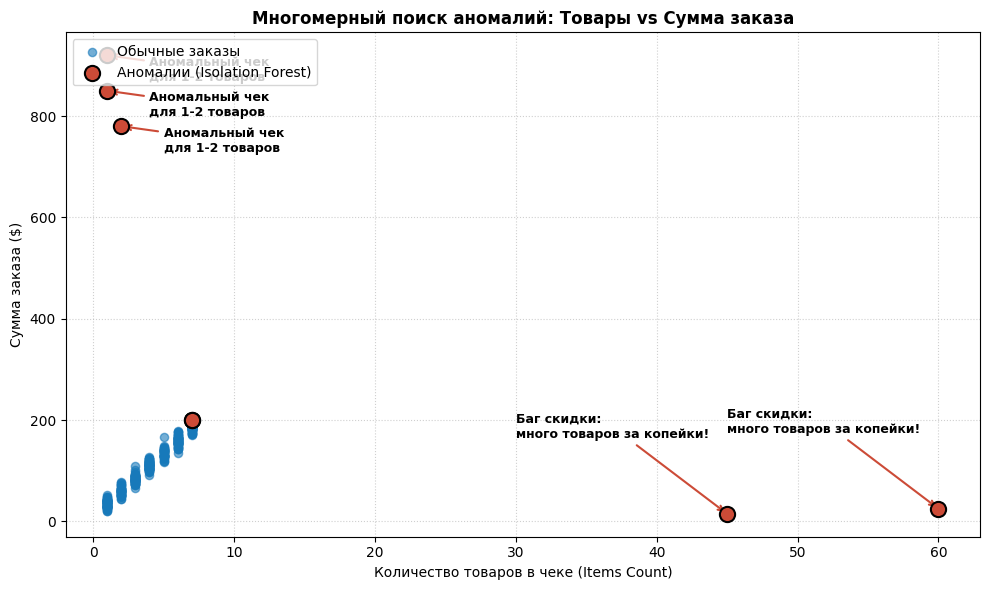

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

normal_mask = df_orders['is_anomaly'] == 1
anom_mask = df_orders['is_anomaly'] == -1

ax.scatter(df_orders[normal_mask]['items_count'], df_orders[normal_mask]['amount'],
           color='#1779ba', alpha=0.6, s=35, label='Обычные заказы')
ax.scatter(df_orders[anom_mask]['items_count'], df_orders[anom_mask]['amount'],
           color='#cc4b37', s=120, edgecolor='black', linewidth=1.5, zorder=5, label='Аномалии (Isolation Forest)')

# Аннотируем баги
for _, row in df_orders[anom_mask].iterrows():
    if row['items_count'] > 30:
        ax.annotate('Баг скидки:\nмного товаров за копейки!', xy=(row['items_count'], row['amount']),
                    xytext=(row['items_count']-15, row['amount']+150),
                    arrowprops=dict(arrowstyle="->", color='#cc4b37', lw=1.5), fontweight='bold', fontsize=9)
    elif row['amount'] > 700:
        ax.annotate('Аномальный чек\nдля 1-2 товаров', xy=(row['items_count'], row['amount']),
                    xytext=(row['items_count']+3, row['amount']-50),
                    arrowprops=dict(arrowstyle="->", color='#cc4b37', lw=1.5), fontweight='bold', fontsize=9)

ax.set_title('Многомерный поиск аномалий: Товары vs Сумма заказа', fontsize=12, fontweight='bold')
ax.set_xlabel('Количество товаров в чеке (Items Count)')
ax.set_ylabel('Сумма заказа ($)')
ax.legend(loc='upper left')
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Доля аномалий в датасете
Рассчитайте точную долю выявленных аномалий от общего объема заказов.

In [4]:
### ВАШ КОД ЗДЕСЬ
anomaly_share = (df_orders['is_anomaly'] == -1).mean()

print(f"Доля аномалий: {anomaly_share:.2%}")
assert 0.005 <= anomaly_share <= 0.05, "Доля аномалий должна соответствовать contamination ~1.5%"
print("✅ Тест успешно пройден!")

Доля аномалий: 1.73%
✅ Тест успешно пройден!


### 💼 Что делать с найденными аномалиями?
Никогда не удаляйте аномалии молча:
1. Заведите тикет инженерам, если это баг расчета скидки.
2. Передайте в отдел безопасности, если это признаки фрода.
3. Исключите из расчетных метрик A/B теста, чтобы один выброс не сломал весь эксперимент.